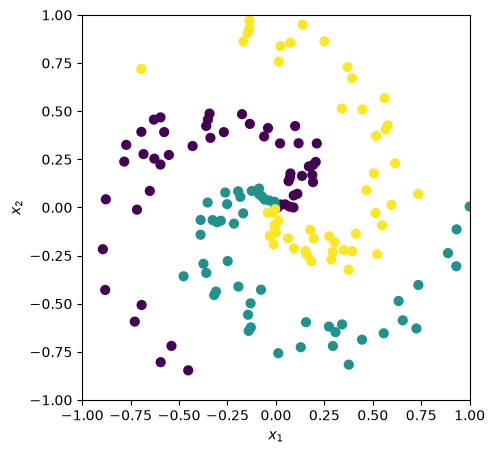

In [8]:
#################################################
#Edit to try different scenarios
#################################################
N = 50 # number of points per branch
K = 3  # number of branches
mag_noise = 0.3  # controls how much noise gets added to the data
dTheta    = 4    # difference in theta in each branch
#################################################

import matplotlib.pyplot as plt
import numpy as np

N_train = N*K # total number of points in the training set
x_train = np.zeros((N_train,2)) # initialize matrix containing the 2-dimensional datapoints
y_train = np.zeros(N_train, dtype='uint8') # initialize labels, positive integer

### Data generation: ###
for j in range(K):
  ix = range(N*j,N*(j+1))
  r  = np.linspace(0.01,1,N) # radius
  th = np.linspace(j*(2*np.pi)/K,j*(2*np.pi)/K + dTheta,N) + np.random.randn(N)*mag_noise # distribute points about theta curve
  x_train[ix] = np.c_[r*np.cos(th), r*np.sin(th)]
  y_train[ix] = j

### Plot the data set: ###
fig = plt.figure(1, figsize=(5,5))
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=40)#, cmap=plt.cm.Spectral)
plt.xlim([-1,1])
plt.ylim([-1,1])
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.savefig('spiral_data.pdf', bbox_inches="tight")
plt.show()


In [2]:
%matplotlib inline

In [5]:
%run ./functions.ipynb

In [ ]:
####################################################
#Next make a neural net to find ideal hyper-parameters for us
#{activation function, learning rate, number of hidden layers (capped), size of hidden layers (capped)
#####################################################

In [ ]:
#should be careful with mapping, especially with categorical variable like activation function

In [26]:
%run ./nnFornnHP.ipynb

In [3]:
import itertools

#make set of possible hidden layers given range of number of hidden layers (pos_len) and possible size of each hidden layer (pos_size)
pos_len    = [2, 3]
pos_size   = [4, 8]
all_arrays = []
for length in pos_len:
    # repeat=length tells it how many items to pick for each combination
    for combo in itertools.product(pos_size, repeat=length):
        all_arrays.append(list(combo))



--- BEGINNING NEURAL ARCHITECTURE SEARCH ---
Starting Neural Architecture Search...
Episode 01 | Reward: 0.5133 | Params: {'activation': 'sigmoid', 'learning_rate': 1.0, 'num_layers': 2, 'layer_sizes': [4, 4]}
Episode 02 | Reward: 0.4117 | Params: {'activation': 'gauss', 'learning_rate': 2.0, 'num_layers': 3, 'layer_sizes': [4, 4, 4]}
Episode 03 | Reward: 0.3732 | Params: {'activation': 'softmax', 'learning_rate': 0.1, 'num_layers': 2, 'layer_sizes': [4, 4]}
Episode 04 | Reward: 0.4933 | Params: {'activation': 'softmax', 'learning_rate': 0.5, 'num_layers': 3, 'layer_sizes': [4, 8, 8]}
Episode 05 | Reward: 0.8661 | Params: {'activation': 'relu', 'learning_rate': 1.0, 'num_layers': 2, 'layer_sizes': [8, 4]}
Episode 06 | Reward: 0.4066 | Params: {'activation': 'sigmoid', 'learning_rate': 1.0, 'num_layers': 3, 'layer_sizes': [4, 4, 8]}
Episode 07 | Reward: 0.6999 | Params: {'activation': 'relu', 'learning_rate': 0.1, 'num_layers': 2, 'layer_sizes': [8, 4]}
Episode 08 | Reward: 0.6749 | Par

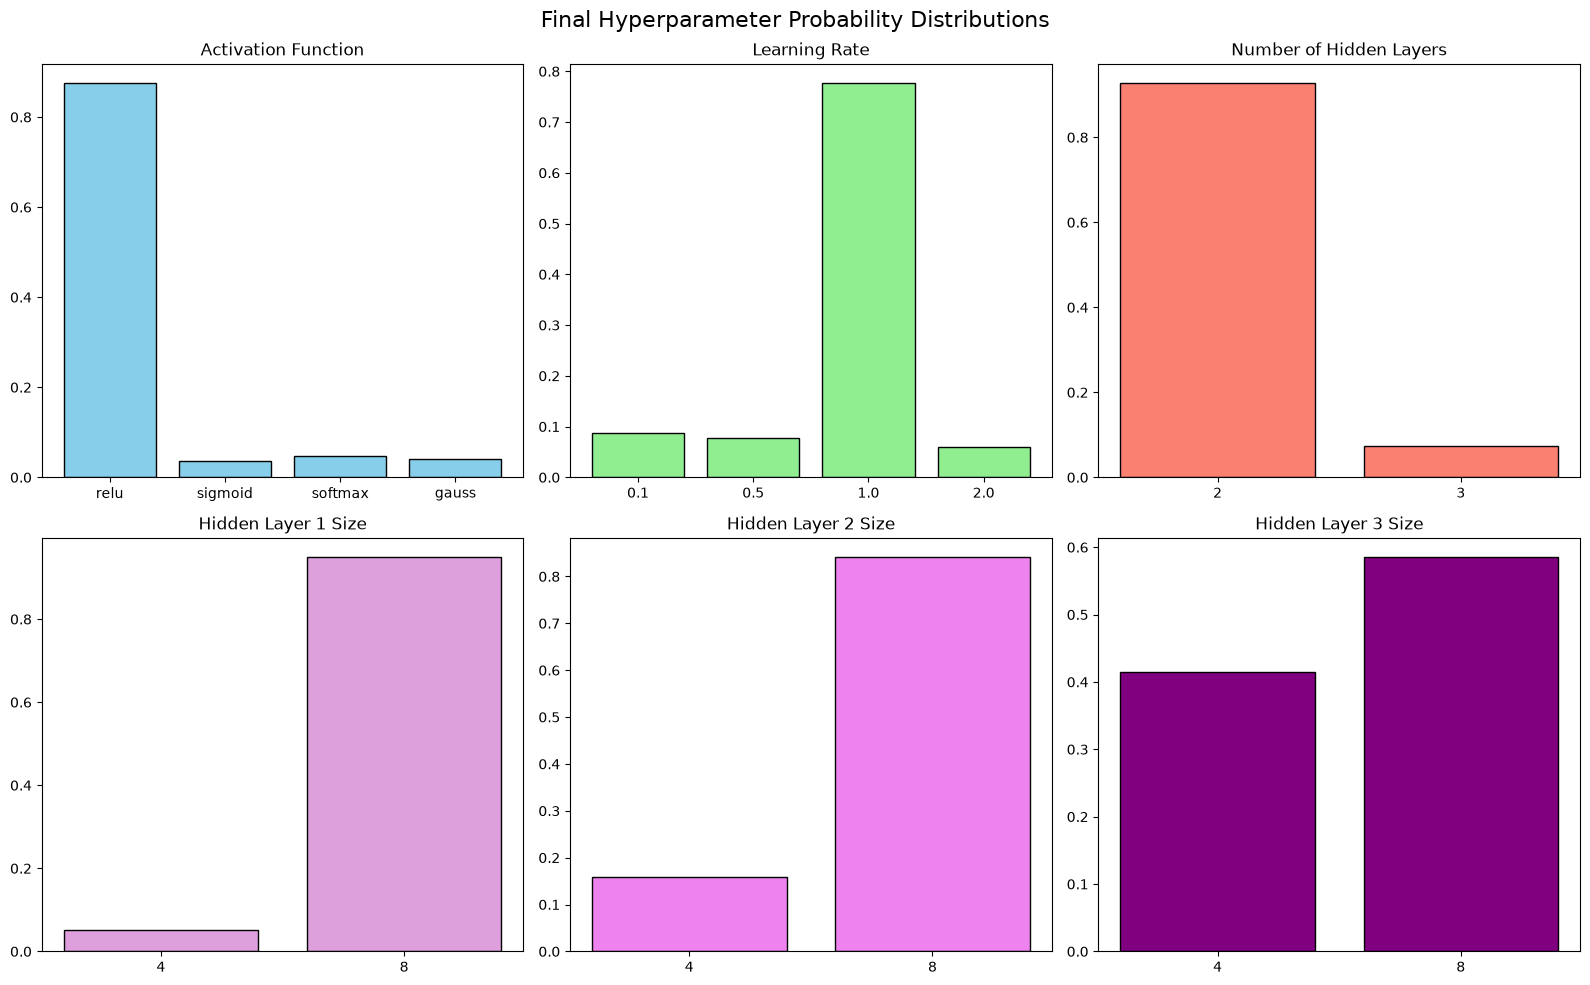

In [27]:
import math

print("--- BEGINNING NEURAL ARCHITECTURE SEARCH ---")
# Pass the search bounds into the optimizer
nas_search = NASOptimizer(pos_len, pos_size, controller_lr=0.01)

optimal_params, act_probs, lr_probs, layers_probs, size_probs_list = nas_search.optimize(
    x_train, y_train, K, search_episodes=50, N_epochs=1000
)

best_act = optimal_params['activation']
best_lr = optimal_params['learning_rate']
best_layers = optimal_params['num_layers']
mid_size_array = optimal_params['layer_sizes']

print("\n--- TRAINING FINAL MODEL WITH OPTIMAL HYPERPARAMETERS ---")
print(f"Configuration: Act={best_act.upper()}, LR={best_lr}, Layers={best_layers}, Array={mid_size_array}")

# --- Dynamically scaled Plotting Grid ---
max_layers = nas_search.controller.max_layers
total_plots = 3 + max_layers # 3 fixed plots (act, lr, num_layers) + independent sizes

# Define a 3-column grid and calculate how many rows are needed
cols = 3
rows = math.ceil(total_plots / cols)

fig, axs = plt.subplots(rows, cols, figsize=(16, 5 * rows))
fig.suptitle('Final Hyperparameter Probability Distributions', fontsize=16)

# Flatten the axes array so we can iterate through it easily
axs = axs.flatten()

activation_labels = list(nas_search.controller.act_map.values())
lr_labels = [str(v) for v in nas_search.controller.lr_map.values()]
layers_labels = [str(v) for v in nas_search.controller.layers_map.values()]
size_labels = [str(v) for v in nas_search.controller.size_map.values()]

axs[0].bar(activation_labels, act_probs, color='skyblue', edgecolor='black')
axs[0].set_title('Activation Function')

axs[1].bar(lr_labels, lr_probs, color='lightgreen', edgecolor='black')
axs[1].set_title('Learning Rate')

axs[2].bar(layers_labels, layers_probs, color='salmon', edgecolor='black')
axs[2].set_title('Number of Hidden Layers')

# Plot a graph for every potential hidden layer
colors = ['plum', 'violet', 'purple', 'orchid', 'mediumpurple'] # Add more colors if searching >5 layers
for i in range(max_layers):
    c = colors[i % len(colors)]
    axs[3 + i].bar(size_labels, size_probs_list[i], color=c, edgecolor='black')
    axs[3 + i].set_title(f'Hidden Layer {i+1} Size')

# Turn off any empty subplots to keep the image clean
for i in range(total_plots, len(axs)):
    fig.delaxes(axs[i])

plt.tight_layout()
plt.savefig('hyperparameter_distributions.pdf', bbox_inches="tight")
plt.show()

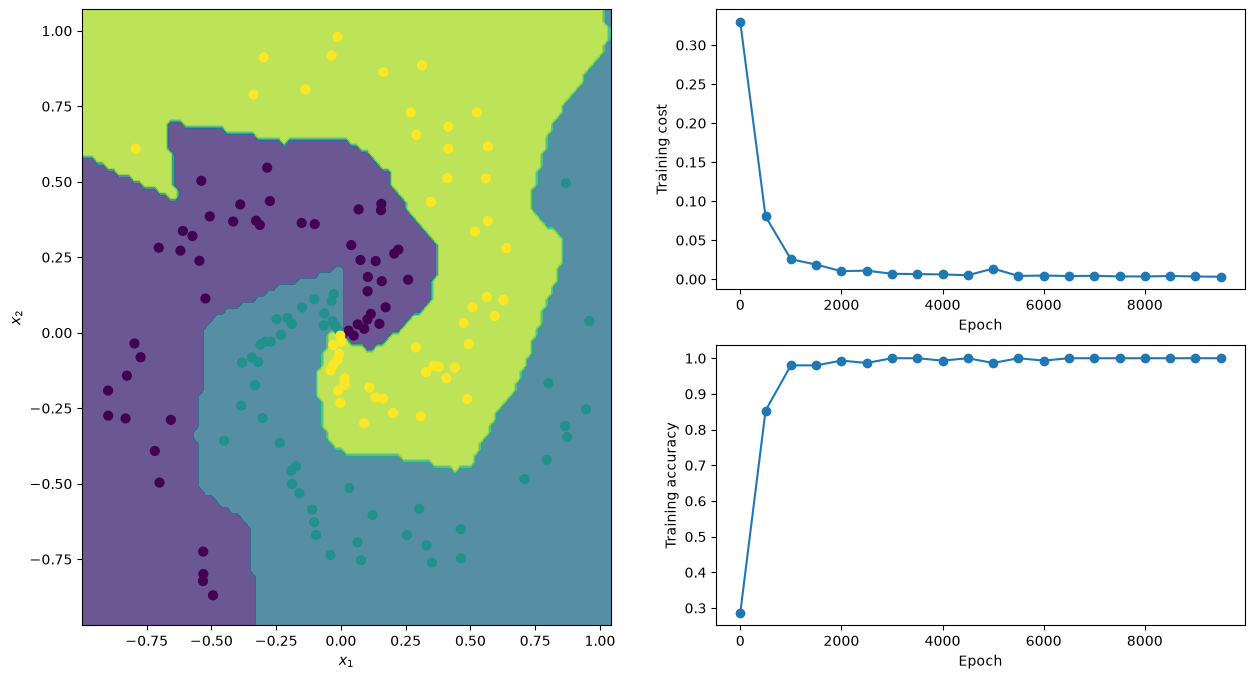

[RELU] Iteration 9500:
  Training cost 0.003078
  Training accuracy 1.000000

Saved spiral_results_OPTIMIZED_relu.pdf
Final RELU Training cost 0.002884
Final RELU Training accuracy 1.000000



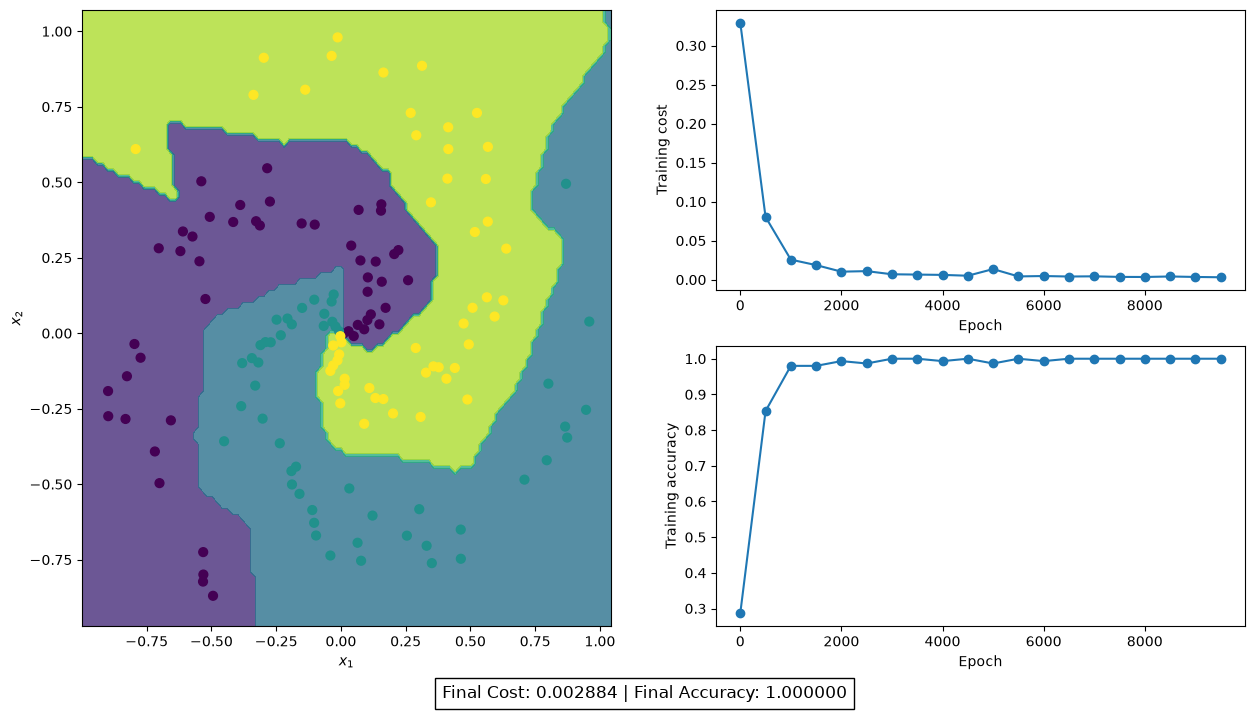

In [35]:
# Setup the final model using original function
model, x_train_tensor, y_onehot, optimizer, cost_func = setup_model_and_data(
    x_train, y_train, K, mid_size_array, best_lr, N_epochs, best_act
)

epoch_list    = []
cost_training = []
acc_training  = []

# Execute the full training loop with live plotting
for epoch in range(N_epochs):
    optimizer.zero_grad()
    NN_output = model(x_train_tensor)
    cost = cost_func(NN_output, y_onehot)
    cost.backward()
    optimizer.step()

    # Update the plot and print results every 500 epochs
    if epoch % 500 == 0:
        predicted_class = np.argmax(NN_output.detach().numpy(), axis=1)
        accuracy = np.mean(predicted_class == y_train)

        epoch_list.append(epoch)
        cost_training.append(cost.detach().numpy())
        acc_training.append(accuracy)

        fig = plt.figure(2, figsize=(15,8))
        fig.subplots_adjust(hspace=.3, wspace=.3)
        plt.clf()

        updatePlot(model, epoch_list, cost_training, acc_training)

        display.display(plt.gcf())
        print(f"[{best_act.upper()}] Iteration {epoch}:\n  Training cost {cost:.6f}\n  Training accuracy {accuracy:.6f}\n")

        if epoch < N_epochs - 500:
            display.clear_output(wait=True)



# Save the final demonstration plot
metrics_text = f"Final Cost: {cost:.6f} | Final Accuracy: {accuracy:.6f}"
plt.figtext(0.5, 0.02, metrics_text, ha="center", fontsize=12, bbox={"facecolor":"white", "pad":5})

filename = f'spiral_results_OPTIMIZED_{best_act}.pdf'
plt.savefig(filename, bbox_inches="tight")

print(f"Saved {filename}")
print(f"Final {best_act.upper()} Training cost {cost:.6f}\nFinal {best_act.upper()} Training accuracy {accuracy:.6f}\n")